In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
raw_df = pd.read_csv('test_credit_fraud.csv')

raw_df.info()
raw_df.shape
raw_df.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 299984 entries, 0 to 299983
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            299984 non-null  int64  
 1   amount_usd                    299984 non-null  float64
 2   hours_since_last_txn          299984 non-null  float64
 3   txn_count_last_24h            299984 non-null  int64  
 4   distance_from_home_km         299984 non-null  float64
 5   card_age_months               299984 non-null  int64  
 6   customer_age                  299984 non-null  int64  
 7   account_balance_usd           299984 non-null  float64
 8   cvv_retry_count               299984 non-null  int64  
 9   velocity_score                299984 non-null  float64
 10  time_of_day_hour              299984 non-null  int64  
 11  day_of_week                   299984 non-null  int64  
 12  merchant_risk_score           299984 non-null  float64


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,...,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,...,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,...,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
3,699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,...,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
4,699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,...,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False
5,699965,46.30,0.97,1,0.90,44,20,2369.53,0,13.5,...,Mastercard,Biometric,POS,iPhone,False,False,False,False,False,False
6,699966,81.33,1.91,3,20.91,47,43,2247.89,0,19.4,...,Visa,3D Secure,POS,iPhone,False,False,False,False,False,False
7,699967,35.68,7.10,2,15.81,47,36,511.73,0,11.2,...,Mastercard,3D Secure,Online,Android Phone,False,False,False,False,False,False
8,699968,35.87,1.36,1,6.65,44,70,706.67,0,23.3,...,RuPay,PIN,Online,Android Phone,False,True,False,False,False,False
9,699969,11.07,4.36,3,5.33,54,19,533.30,0,21.3,...,Visa,3D Secure,Online,Android Phone,False,False,False,False,False,False


In [3]:
raw_df.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes
count,299984.000000,299984.000000,299984.000000,299984.000000,299984.000000,299984.000000,299984.000000,299984.000000,299984.000000,299984.00000,299984.00000,299984.000000,299984.000000,299984.000000
mean,849951.500000,79.921195,6.640317,2.983806,13.602890,46.840748,51.424259,2071.467998,0.085368,18.93846,11.74694,2.971338,35.217383,0.153922
std,86598.065914,201.853988,6.306074,1.497836,11.610564,5.589432,17.891769,3430.012434,0.289092,10.86947,6.87109,1.997228,12.622723,0.383142
min,699960.000000,1.000000,0.010000,0.000000,0.000000,24.000000,18.000000,58.180000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000
25%,774955.750000,15.760000,2.110000,2.000000,4.440000,43.000000,38.000000,834.010000,0.000000,11.40000,6.00000,1.000000,26.400000,0.000000
50%,849951.500000,27.280000,4.720000,3.000000,10.270000,47.000000,52.000000,1388.540000,0.000000,18.70000,12.00000,3.000000,34.200000,0.000000
75%,924947.250000,43.170000,9.220000,4.000000,19.780000,51.000000,66.000000,2524.160000,0.000000,26.10000,18.00000,5.000000,42.800000,0.000000
max,999943.000000,6098.420000,51.870000,10.000000,60.470000,72.000000,81.000000,88577.930000,3.000000,73.60000,23.00000,6.000000,100.000000,4.000000


In [4]:
raw_df.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

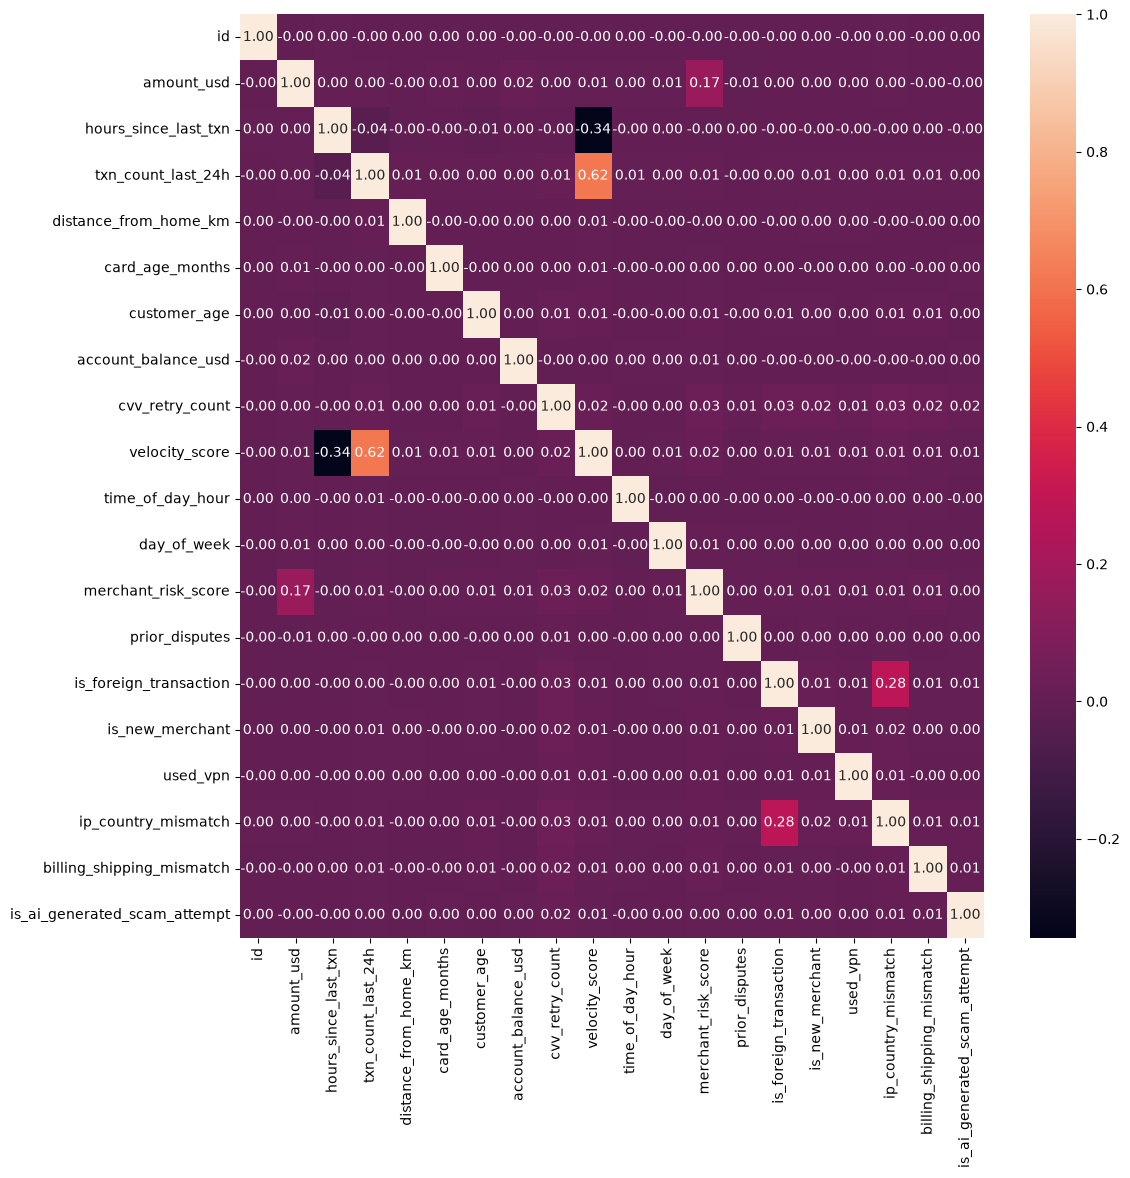

In [5]:
plt.figure(figsize=(12, 12))
sns.heatmap(raw_df.corr(numeric_only=True),annot=True, fmt='.2f')
plt.show()

<Axes: xlabel='amount_usd', ylabel='Count'>

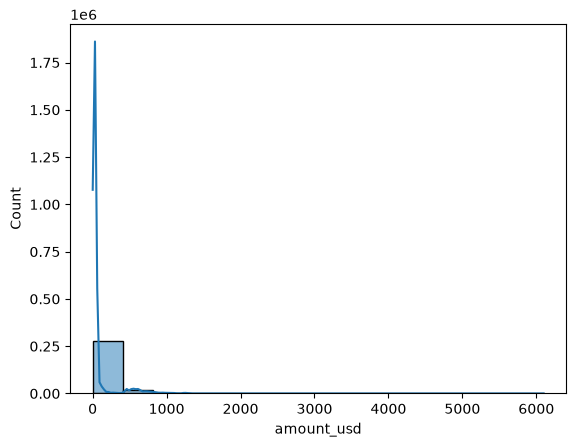

In [6]:
sns.histplot(raw_df['amount_usd'], bins=15, kde=True)

<Axes: xlabel='hours_since_last_txn', ylabel='Count'>

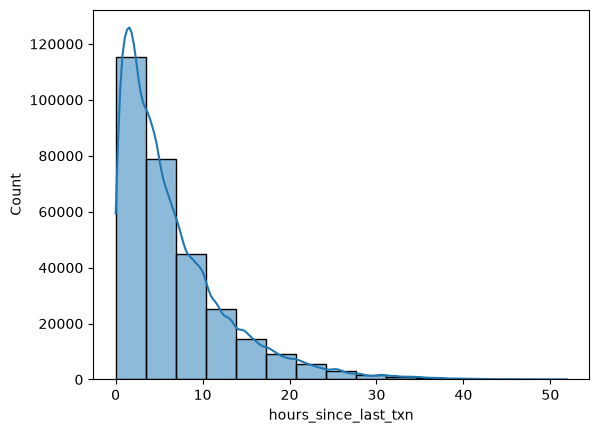

In [7]:
sns.histplot(raw_df['hours_since_last_txn'], bins=15, kde=True)

In [8]:
raw_df.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

<Axes: xlabel='txn_count_last_24h', ylabel='Count'>

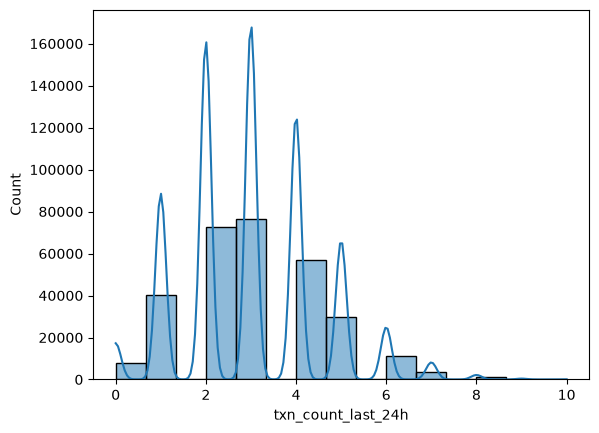

In [9]:
sns.histplot(raw_df['txn_count_last_24h'], bins=15, kde=True)


<Axes: xlabel='customer_age', ylabel='card_age_months'>

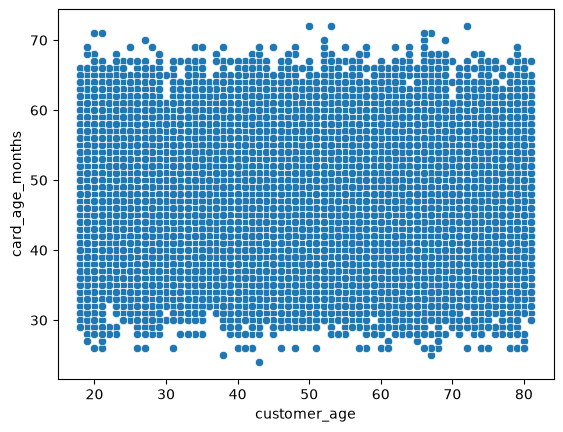

In [10]:
sns.scatterplot(data=raw_df, x=raw_df['customer_age'], y=raw_df['card_age_months'])

In [11]:
raw_df.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

<Axes: xlabel='account_balance_usd', ylabel='Count'>

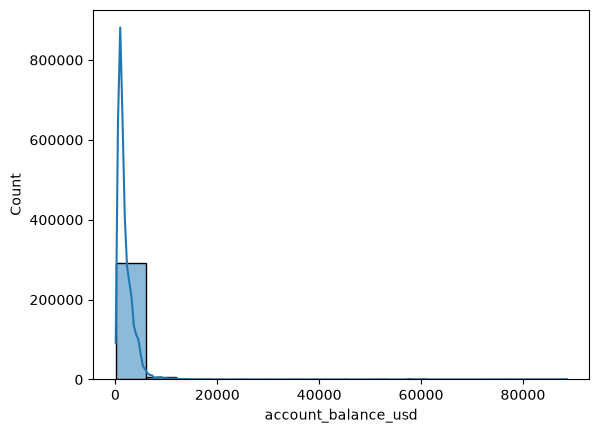

In [12]:
sns.histplot(raw_df['account_balance_usd'], bins=15, kde=True)

<Axes: xlabel='cvv_retry_count', ylabel='count'>

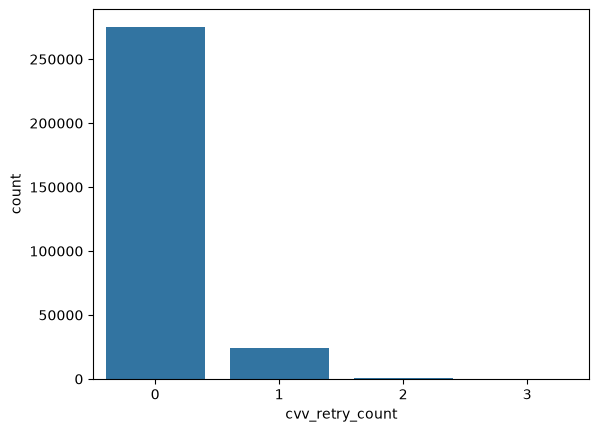

In [13]:
sns.countplot(data=raw_df, x=raw_df['cvv_retry_count'])

In [14]:
raw_df.shape

(299984, 25)

<Axes: xlabel='velocity_score', ylabel='Count'>

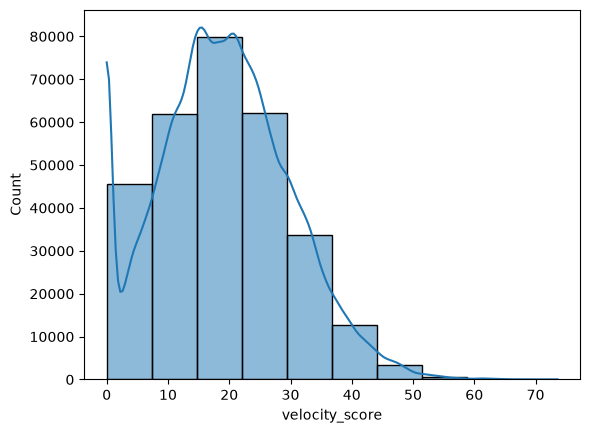

In [15]:
sns.histplot(raw_df['velocity_score'], bins=10, kde=True)

In [16]:
raw_df.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

<Axes: xlabel='time_of_day_hour'>

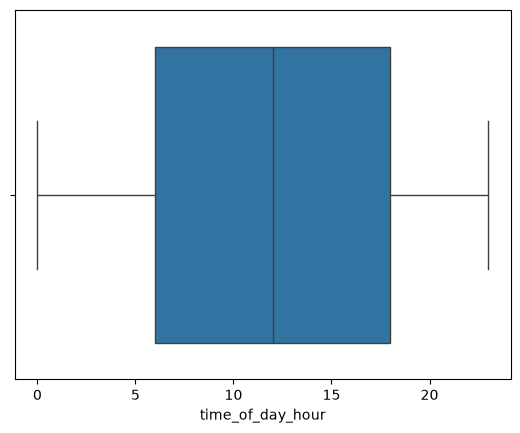

In [17]:
sns.boxplot(data=raw_df, x = raw_df['time_of_day_hour'])

<Axes: xlabel='day_of_week'>

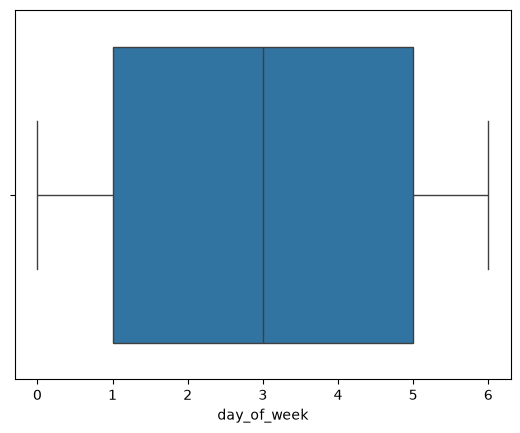

In [18]:
sns.boxplot(data=raw_df, x = raw_df['day_of_week'])

<Axes: xlabel='merchant_risk_score', ylabel='Count'>

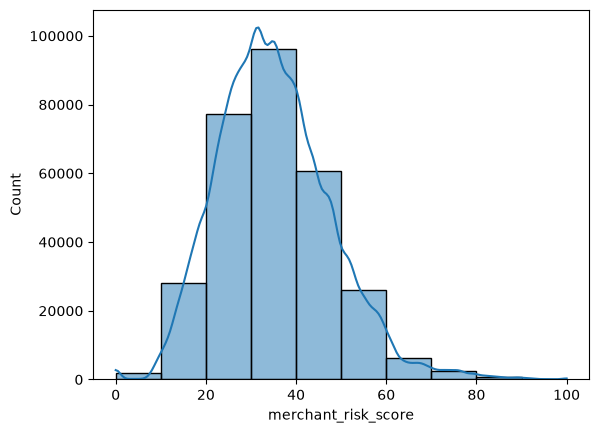

In [19]:
sns.histplot(raw_df['merchant_risk_score'], bins=10, kde=True)

<Axes: xlabel='merchant_risk_score', ylabel='merchant_category'>

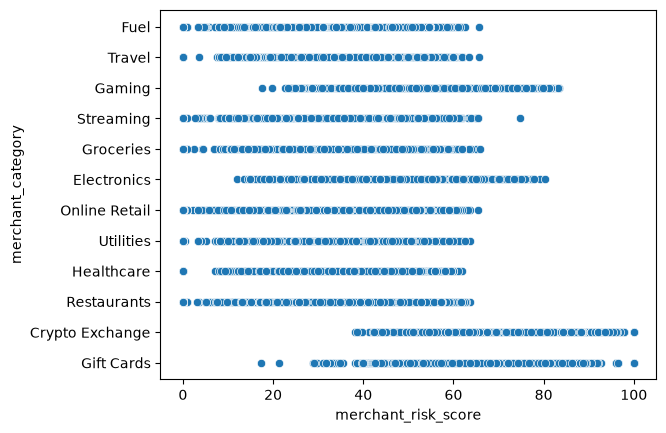

In [20]:
sns.scatterplot(data=raw_df, x = raw_df['merchant_risk_score'], y = raw_df['merchant_category'])

In [21]:
raw_df.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

<Axes: xlabel='prior_disputes', ylabel='count'>

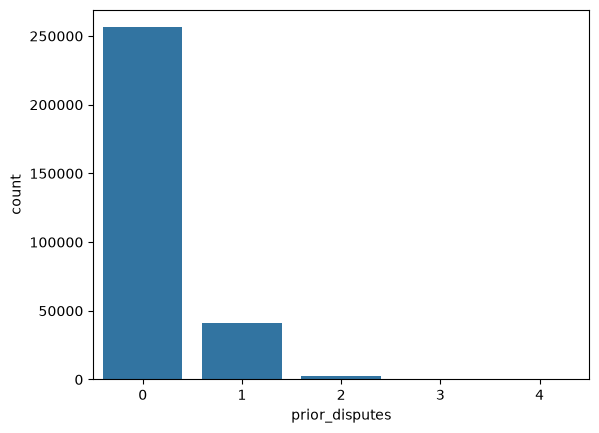

In [22]:
sns.countplot(data=raw_df,x= raw_df['prior_disputes'])

<Axes: xlabel='card_type', ylabel='count'>

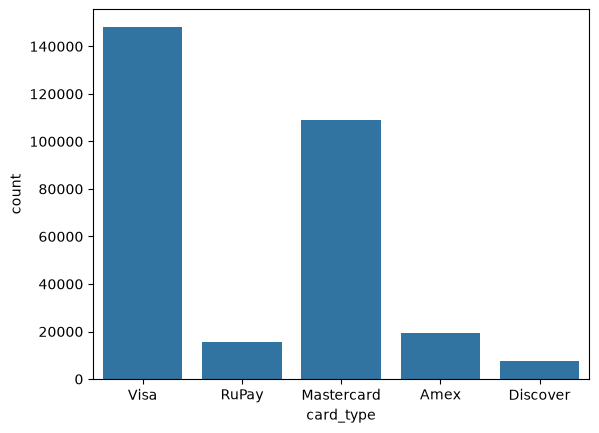

In [23]:
sns.countplot(data=raw_df, x = raw_df['card_type'])

<Axes: xlabel='auth_method', ylabel='count'>

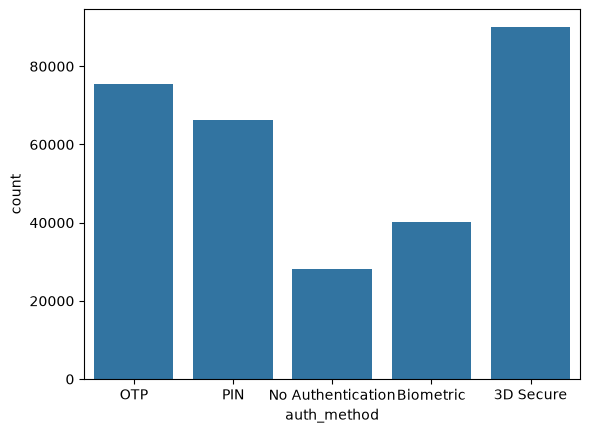

In [24]:
sns.countplot(data=raw_df, x = raw_df['auth_method'])

In [25]:
raw_df.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

<Axes: xlabel='channel', ylabel='count'>

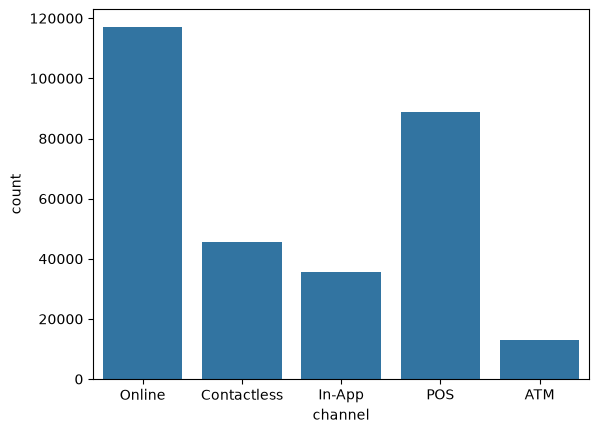

In [26]:
sns.countplot(data=raw_df, x = raw_df['channel'])

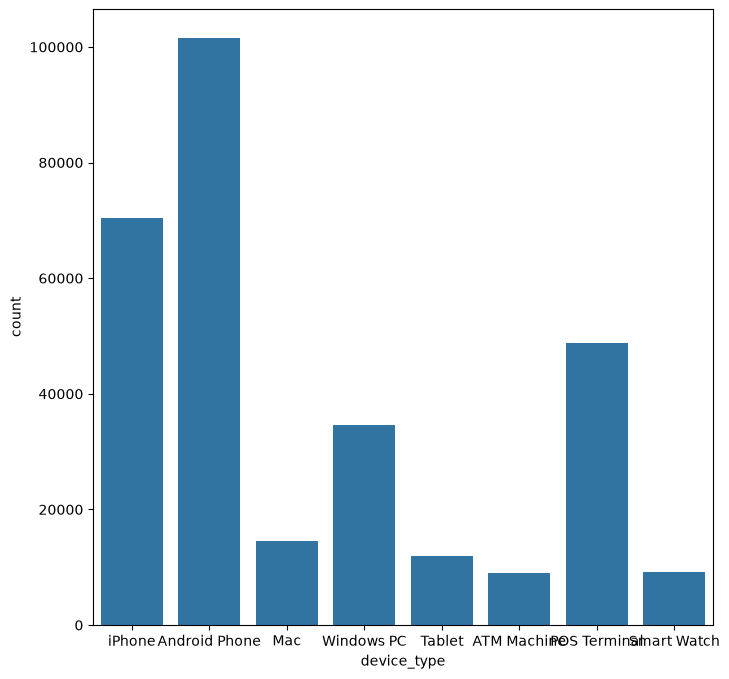

In [27]:
plt.figure(figsize=(8, 8))
sns.countplot(data=raw_df, x = raw_df['device_type'])
plt.show()

In [28]:
raw_df.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

<Axes: xlabel='is_foreign_transaction', ylabel='count'>

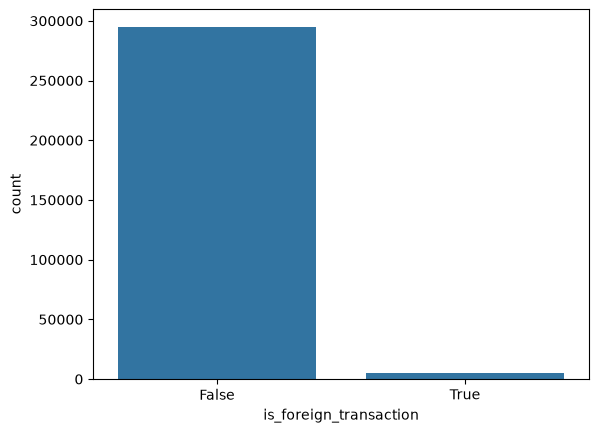

In [29]:
sns.countplot(data=raw_df, x = raw_df['is_foreign_transaction'])

<Axes: xlabel='is_new_merchant', ylabel='count'>

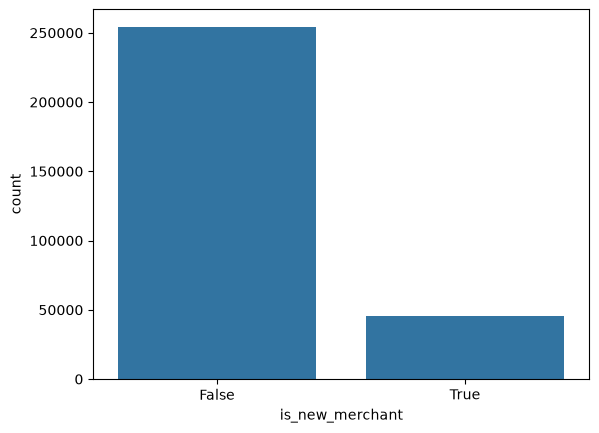

In [30]:
sns.countplot(data=raw_df, x = raw_df['is_new_merchant'])

<Axes: xlabel='used_vpn', ylabel='count'>

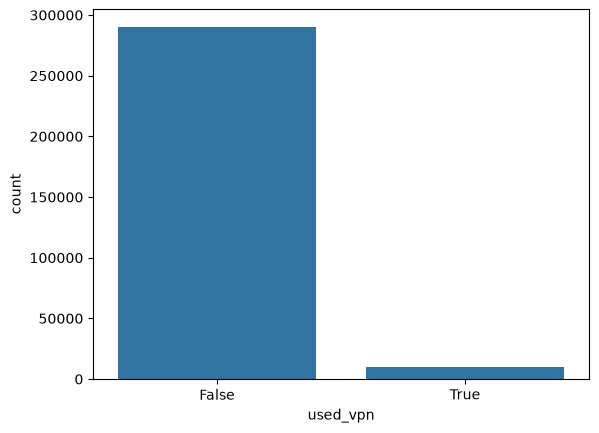

In [31]:
sns.countplot(data=raw_df, x = raw_df['used_vpn'])

<Axes: xlabel='ip_country_mismatch', ylabel='count'>

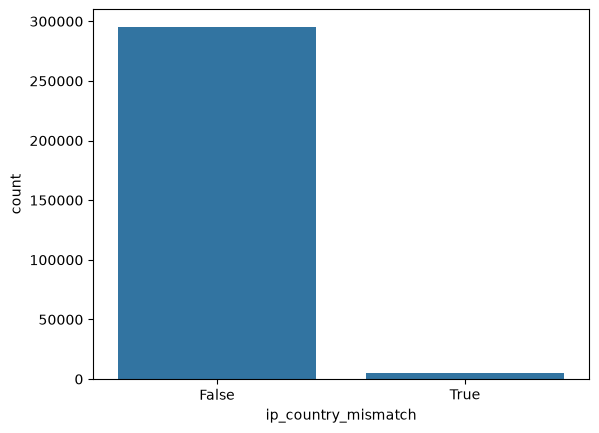

In [32]:
sns.countplot(data=raw_df, x = raw_df['ip_country_mismatch'])

<Axes: xlabel='billing_shipping_mismatch', ylabel='count'>

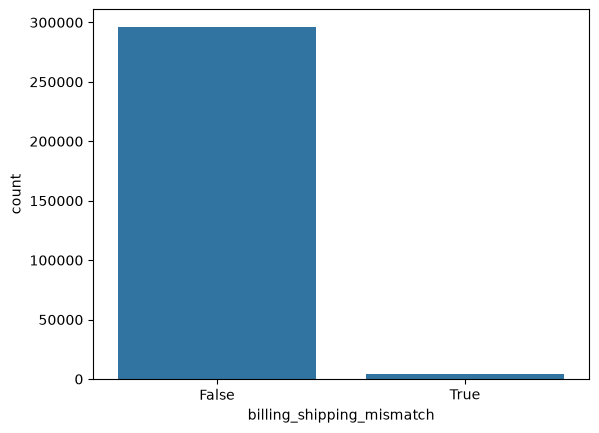

In [33]:
sns.countplot(data=raw_df, x = raw_df['billing_shipping_mismatch'])

<Axes: xlabel='is_ai_generated_scam_attempt', ylabel='count'>

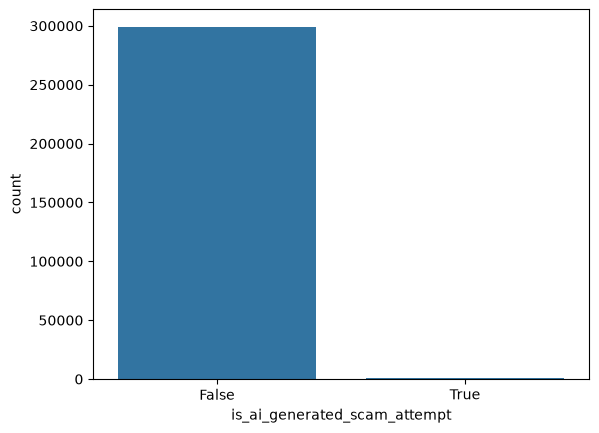

In [34]:
sns.countplot(data=raw_df, x = raw_df['is_ai_generated_scam_attempt'])

In [35]:
raw_df['is_ai_generated_scam_attempt'].value_counts()

is_ai_generated_scam_attempt
False    298955
True       1029
Name: count, dtype: int64

In [36]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299984 entries, 0 to 299983
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            299984 non-null  int64  
 1   amount_usd                    299984 non-null  float64
 2   hours_since_last_txn          299984 non-null  float64
 3   txn_count_last_24h            299984 non-null  int64  
 4   distance_from_home_km         299984 non-null  float64
 5   card_age_months               299984 non-null  int64  
 6   customer_age                  299984 non-null  int64  
 7   account_balance_usd           299984 non-null  float64
 8   cvv_retry_count               299984 non-null  int64  
 9   velocity_score                299984 non-null  float64
 10  time_of_day_hour              299984 non-null  int64  
 11  day_of_week                   299984 non-null  int64  
 12  merchant_risk_score           299984 non-null  float64


In [37]:
raw_df.dtypes

id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool


In [38]:
raw_df['is_foreign_transaction'] = raw_df['is_foreign_transaction'].map({True: 1, False: 0})

In [39]:
raw_df['ip_country_mismatch'] = raw_df['ip_country_mismatch'].map({True: 1, False: 0})

In [40]:
raw_df['is_new_merchant'] = raw_df['is_new_merchant'].map({True:1, False:0})

In [41]:
raw_df['used_vpn'] = raw_df['used_vpn'].map({True:1, False:0})

In [42]:
raw_df['billing_shipping_mismatch'] = raw_df['billing_shipping_mismatch'].map({True:1, False:0})

In [43]:
raw_df['is_ai_generated_scam_attempt'] = raw_df['is_ai_generated_scam_attempt'].map({True:1, False:0})

In [44]:
raw_df.isnull().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
dtype: int64

In [45]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.tree import DecisionTreeClassifier

In [46]:
from sklearn.metrics import r2_score, roc_curve, roc_auc_score, confusion_matrix, classification_report, accuracy_score, balanced_accuracy_score, f1_score, average_precision_score

In [47]:
X = raw_df.drop(columns=['is_ai_generated_scam_attempt', 'id'])
y = raw_df['is_ai_generated_scam_attempt'].astype("int8")

In [48]:
categorical_columns = X.select_dtypes(include='object').columns
numerical_columns = X.select_dtypes(exclude='object').columns

preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_columns),
    ('numerical', StandardScaler(), numerical_columns)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

tuning_size = min(20000, len(X_train))
X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=tuning_size,
    stratify=y_train,
    random_state=42
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    model,
    X_tune,
    y_tune,
    cv=cv,
    scoring='roc_auc',
    n_jobs=1
)

print(f'Baseline CV ROC-AUC: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}')

param_grid = {
    'classifier__C': [0.1, 1, 10],
    'classifier__class_weight': ['balanced', None]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=1,
    refit=True
)

grid_search.fit(X_tune, y_tune)
model = grid_search.best_estimator_
model.fit(X_train, y_train)

print(f'Best CV ROC-AUC: {grid_search.best_score_:.4f}')
print('Best parameters:', grid_search.best_params_)

Baseline CV ROC-AUC: 0.7331 +/- 0.0149
Best CV ROC-AUC: 0.7331
Best parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}


In [49]:
base_learner = [
    ('dt', Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(random_state=42))
    ])),
    ('svm', Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', SVC(probability=True, kernel='rbf', random_state=42))
    ])),
    ('lr', Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=2000))
    ]))
]

In [50]:
meta_learner = KNeighborsClassifier(n_neighbors=5)

In [51]:
stacking_clf = StackingClassifier(
    estimators=base_learner,
    final_estimator=meta_learner,
    cv=5
)

In [52]:
stacking_clf.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('dt', ...), ('svm', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",KNeighborsClassifier()
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int8](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[Pipeline(step...m_state=42))]), Pipeline(step...m_state=42))]), Pipeline(step..._iter=2000))])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0",

In [58]:
y_prediction = stacking_clf.predict(X_valid)

In [60]:
accuracy_score(y_prediction, y_valid)

0.9965664949914163

In [54]:
y_score = model.predict_proba(X_valid)[:, 1]

threshold = 0.5
y_pred = (y_score >= threshold).astype("int8")    

In [55]:
y_pred

array([0, 0, 0, ..., 1, 0, 0], shape=(59997,), dtype=int8)

In [61]:
print(confusion_matrix(y_valid, y_prediction))
print(classification_report(y_valid, y_prediction, zero_division=0))
print("Average precision:", average_precision_score(y_valid, y_prediction))

[[59791     0]
 [  206     0]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     59791
           1       0.00      0.00      0.00       206

    accuracy                           1.00     59997
   macro avg       0.50      0.50      0.50     59997
weighted avg       0.99      1.00      0.99     59997

Average precision: 0.0034335050085837625


In [65]:
accuracy_score(y_prediction, y_valid)

0.9965664949914163

In [66]:
test_df = pd.read_csv("test_credit_fraud.csv")
test_X = test_df.drop(columns=["id"])

submission = pd.DataFrame({
    "id": test_df["id"],
    "is_fraud": model.predict_proba(test_X)[:, 1],
})
submission.to_csv("submission.csv", index=False)